# Cleaning and Analyzing Global Coffee Trade Data

In this project I look at three coffee data files: how much coffee countries **export**, how much they **import**, and how much they **produce**. First I clean the data so it is easy to use, then I answer some questions about coffee trade, and finally I make some charts.

## Setup

I load the tools I need.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

## Part 1 - Load and Look at the Data

I load the three files and check their size, their column types, and the list of countries in the export and import files.

In [2]:
export_df = pd.read_csv('Coffee_export.csv')
import_df = pd.read_csv('Coffee_import.csv')
production_df = pd.read_csv('Coffee_production.csv')

export_df.head()

,Country,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,Total_export
0,Angola,5040000,4260000,4800000,2340000,480000,2460000,3120000,3000000,3240000,3000000,1320000,840000,540000,1020000,360000,300000,300000,240000,360000,420000,240000,480000,480000,360000,540000,660000,660000,540000,540000,1380000,43320000
1,Bolivia (Plurinational State of),9360000,4440000,5760000,2820000,5040000,5640000,7380000,6660000,5820000,7440000,6360000,4200000,4740000,4380000,5580000,5040000,5580000,5040000,4080000,4980000,4680000,4440000,3780000,3300000,3720000,1800000,1320000,1560000,1320000,1200000,137460000
2,Brazil,1016160000,1270980000,1127460000,1070280000,1036380000,868080000,915060000,1008060000,1088640000,1388940000,1080960000,1390320000,1678920000,1542660000,1588680000,1571880000,1642140000,1691040000,1770600000,1822680000,1990020000,2028360000,1712940000,1899060000,-2147483648,-2147483648,2056140000,1855500000,2138220000,-2147483648,33807709056
3,Burundi,35100000,41280000,38760000,25080000,30480000,31680000,13440000,31740000,22440000,24540000,26640000,18180000,17340000,28560000,20340000,22260000,16860000,21360000,15060000,17340000,18420000,13080000,23520000,11700000,15120000,13800000,12240000,10140000,12120000,17580000,646200000
4,Cameroon,156660000,105120000,98760000,42300000,32760000,24420000,33840000,82080000,44760000,69240000,72300000,67500000,38400000,48840000,44040000,42240000,44340000,43260000,31620000,37080000,47640000,29400000,37320000,16320000,22500000,23400000,16860000,14700000,17220000,15000000,1399920000


In [3]:
import_df.head()

,Country,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,Total_import
0,Austria,112800000,123480000,132360000,110160000,85020000,73860000,72600000,77640000,77580000,90000000,75420000,85920000,86820000,80160000,92280000,94620000,96060000,118080000,114060000,78540000,82140000,87120000,93540000,93300000,91500000,90780000,89700000,87600000,85740000,86880000,2765760000
1,Belgium,0,0,0,0,0,0,0,0,0,180180000,209460000,192540000,227520000,229080000,238080000,243780000,276300000,240840000,407520000,354960000,355440000,349680000,340080000,330120000,312720000,332040000,363120000,340620000,344520000,371940000,6240540000
2,Belgium/Luxembourg,120900000,104760000,109680000,123780000,135720000,144060000,151560000,152640000,214800000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1257900000
3,Bulgaria,16080000,12000000,10920000,23820000,27780000,30900000,16320000,17640000,20520000,22020000,16860000,21300000,20580000,24000000,22020000,26460000,26100000,23580000,31020000,31380000,31680000,28920000,33600000,36540000,37260000,40920000,46740000,42420000,44220000,47100000,830700000
4,Croatia,0,0,10080000,9780000,11580000,19200000,19320000,23100000,20340000,21120000,20640000,21120000,22260000,23580000,23280000,23520000,24240000,24840000,24300000,23640000,23640000,23460000,23040000,24780000,25200000,26220000,28740000,26340000,26760000,27960000,622080000


In [4]:
production_df.head()

,Country,Coffee type,1990/91,1991/92,1992/93,1993/94,1994/95,1995/96,1996/97,1997/98,1998/99,1999/00,2000/01,2001/02,2002/03,2003/04,2004/05,2005/06,2006/07,2007/08,2008/09,2009/10,2010/11,2011/12,2012/13,2013/14,2014/15,2015/16,2016/17,2017/18,2018/19,2019/20,Total_production
0,Angola,Robusta/Arabica,3.000000e+06,4.740000e+06,4.680000e+06,1.980000e+06,4.620000e+06,3.720000e+06,4.260000e+06,3.840000e+06,5.100000e+06,3.300000e+06,3.000000e+06,1.260000e+06,3.420000e+06,2.280000e+06,9.000000e+05,1.500000e+06,2.100000e+06,2.160000e+06,2.280000e+06,7.800000e+05,2.100000e+06,1.740000e+06,1.980000e+06,2.100000e+06,2.340000e+06,2.460000e+06,2.700000e+06,2.100000e+06,2.520000e+06,3.120000e+06,8.208000e+07
1,Bolivia (Plurinational State of),Arabica,7.380000e+06,6.240000e+06,7.200000e+06,3.060000e+06,7.020000e+06,8.520000e+06,7.500000e+06,8.460000e+06,8.280000e+06,9.480000e+06,8.880000e+06,5.640000e+06,7.620000e+06,6.180000e+06,9.300000e+06,6.600000e+06,8.760000e+06,6.960000e+06,7.200000e+06,7.680000e+06,7.020000e+06,7.920000e+06,6.300000e+06,7.200000e+06,6.000000e+06,5.040000e+06,4.680000e+06,5.040000e+06,4.980000e+06,4.860000e+06,2.070000e+08
2,Brazil,Arabica/Robusta,1.637160e+09,1.637580e+09,2.076180e+09,1.690020e+09,1.691520e+09,1.083600e+09,1.751820e+09,1.568880e+09,2.205660e+09,2.854680e+09,1.878600e+09,1.881900e+09,2.901120e+09,1.732380e+09,2.356860e+09,1.975980e+09,2.905920e+09,2.334660e+09,3.089460e+09,2.638620e+09,3.325680e+09,2.915520e+09,3.325080e+09,3.281340e+09,3.198300e+09,3.172260e+09,3.407280e+09,3.164400e+09,3.907860e+09,3.492660e+09,7.508298e+10
3,Burundi,Arabica/Robusta,2.922000e+07,4.002000e+07,3.720000e+07,2.358000e+07,3.984000e+07,2.604000e+07,2.406000e+07,1.500000e+07,2.952000e+07,2.106000e+07,2.922000e+07,8.640000e+06,2.724000e+07,2.028000e+07,2.622000e+07,6.180000e+06,2.988000e+07,7.980000e+06,2.472000e+07,6.720000e+06,2.118000e+07,1.224000e+07,2.436000e+07,9.780000e+06,1.488000e+07,1.614000e+07,1.176000e+07,1.212000e+07,1.224000e+07,1.632000e+07,6.236400e+08
4,Ecuador,Arabica/Robusta,9.024000e+07,1.274400e+08,7.110000e+07,1.241400e+08,1.425600e+08,1.132800e+08,1.195800e+08,7.146000e+07,7.236000e+07,7.188000e+07,5.124000e+07,4.758000e+07,3.492000e+07,3.846000e+07,4.680000e+07,5.610000e+07,6.210000e+07,5.700000e+07,4.626000e+07,4.878000e+07,5.124000e+07,4.950000e+07,4.968000e+07,3.996000e+07,3.864000e+07,3.864000e+07,3.870000e+07,3.744000e+07,2.976000e+07,3.354000e+07,1.900380e+09


### How big is each file?

In [5]:
for name, df in [('export', export_df), ('import', import_df), ('production', production_df)]:
    print(f'{name:<12} -> {df.shape[0]} rows and {df.shape[1]} columns')

export       -> 55 rows and 32 columns
import       -> 35 rows and 32 columns
production   -> 55 rows and 33 columns


### What type is each column?

In [6]:
export_df.dtypes

Country           str
1990            int64
1991            int64
1992            int64
1993            int64
1994            int64
1995            int64
1996            int64
1997            int64
1998            int64
1999            int64
2000            int64
2001            int64
2002            int64
2003            int64
2004            int64
2005            int64
2006            int64
2007            int64
2008            int64
2009            int64
2010            int64
2011            int64
2012            int64
2013            int64
2014            int64
2015            int64
2016            int64
2017            int64
2018            int64
2019            int64
Total_export    int64
dtype: object

In [7]:
import_df.dtypes

Country           str
1990            int64
1991            int64
1992            int64
1993            int64
1994            int64
1995            int64
1996            int64
1997            int64
1998            int64
1999            int64
2000            int64
2001            int64
2002            int64
2003            int64
2004            int64
2005            int64
2006            int64
2007            int64
2008            int64
2009            int64
2010            int64
2011            int64
2012            int64
2013            int64
2014            int64
2015            int64
2016            int64
2017            int64
2018            int64
2019            int64
Total_import    int64
dtype: object

In [8]:
production_df.dtypes

Country                 str
Coffee type             str
1990/91             float64
1991/92             float64
1992/93             float64
1993/94             float64
1994/95             float64
1995/96             float64
1996/97             float64
1997/98             float64
1998/99             float64
1999/00             float64
2000/01             float64
2001/02             float64
2002/03             float64
2003/04             float64
2004/05             float64
2005/06             float64
2006/07             float64
2007/08             float64
2008/09             float64
2009/10             float64
2010/11             float64
2011/12             float64
2012/13             float64
2013/14             float64
2014/15             float64
2015/16             float64
2016/17             float64
2017/18             float64
2018/19             float64
2019/20             float64
Total_production    float64
dtype: object

### Which countries are in the export and import files?

I print both lists to see if they match.

In [9]:
export_countries = sorted(export_df['Country'].unique())
import_countries = sorted(import_df['Country'].unique())

print(f'Export file has {len(export_countries)} countries:')
print(export_countries)
print()
print(f'Import file has {len(import_countries)} countries (notice the extra spaces):')
print([repr(c) for c in import_countries])

Export file has 55 countries:
['Angola', 'Bolivia (Plurinational State of)', 'Brazil', 'Burundi', 'Cameroon', 'Central African Republic', 'Colombia', 'Congo', 'Costa Rica', 'Cuba', "Côte d'Ivoire", 'Democratic Republic of Congo', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Gabon', 'Ghana', 'Guatemala', 'Guinea', 'Guyana', 'Haiti', 'Honduras', 'India', 'Indonesia', 'Jamaica', 'Kenya', "Lao People's Democratic Republic", 'Liberia', 'Madagascar', 'Malawi', 'Mexico', 'Nepal', 'Nicaragua', 'Nigeria', 'Panama', 'Papua New Guinea', 'Paraguay', 'Peru', 'Philippines', 'Rwanda', 'Sierra Leone', 'Sri Lanka', 'Tanzania', 'Thailand', 'Timor-Leste', 'Togo', 'Trinidad & Tobago', 'Uganda', 'Venezuela', 'Viet Nam', 'Yemen', 'Zambia', 'Zimbabwe']

Import file has 35 countries (notice the extra spaces):
["'   Austria'", "'   Belgium'", "'   Belgium/Luxembourg'", "'   Bulgaria'", "'   Croatia'", "'   Cyprus'", "'   Czechia'", "'   Denmark'", "'   Estonia'", "'   Finla

The two lists do **not** match. The import names have extra spaces in front of them, and the import file lists countries that *buy* coffee while the export file lists countries that *sell* it. So they are mostly different countries.

## Part 2 - Find the Problems in the Data

Before I clean anything, I check what is wrong with the data.

### Are there any missing values?

In [10]:
print('Missing in export:', int(export_df.isnull().sum().sum()))
print('Missing in import:', int(import_df.isnull().sum().sum()))
print('Missing in production:', int(production_df.isnull().sum().sum()))

Missing in export: 0
Missing in import: 0
Missing in production: 0


### Are any number columns saved as text by mistake?

In [11]:
def text_columns(df, skip):
    return [c for c in df.columns if c not in skip and df[c].dtype == object]

print('Export text columns:', text_columns(export_df, {'Country'}))
print('Import text columns:', text_columns(import_df, {'Country'}))
print('Production text columns:', text_columns(production_df, {'Country', 'Coffee type'}))

Export text columns: []
Import text columns: []
Production text columns: []


### Are there any weird numbers?

Coffee amounts can never be negative, so any negative number is a mistake.

In [12]:
year_cols_export = [c for c in export_df.columns if c not in ('Country', 'Total_export')]
INT32_MIN = -2147483648

bad = (export_df[year_cols_export] == INT32_MIN)
print('Number of bad -2147483648 values in export:', int(bad.values.sum()))
print('Countries with this problem:', export_df.loc[bad.any(axis=1), 'Country'].tolist())

Number of bad -2147483648 values in export: 3
Countries with this problem: ['Brazil']


### What I found

- **Missing values:** there are almost no blank cells, but the export file hides a fake number instead.
- **Bad numbers:** Brazil's export file has the value **-2147483648** in a few years. This is a computer glitch (a number too big that flipped negative). Coffee amounts can't be negative, so I will treat these as missing.
- **Country names:** every country in the import file starts with extra spaces (like `'   Austria'`), which would mess up any matching. The production file also has an extra `Coffee type` column and uses years like `1990/91`.

## Part 3 - Clean the Data

Now I fix each problem I found.

### Fix the country names

I remove the extra spaces and fix a few common name variations so the names match across all three files.

In [13]:
COUNTRY_ALIASES = {
    'USA': 'United States of America',
    'United States': 'United States of America',
    'UK': 'United Kingdom',
    'Russia': 'Russian Federation',
    'Vietnam': 'Viet Nam',
}

def clean_names(df):
    df = df.copy()
    df['Country'] = df['Country'].str.strip().replace(COUNTRY_ALIASES)
    return df

export_df = clean_names(export_df)
import_df = clean_names(import_df)
production_df = clean_names(production_df)

print('Import names now:', list(import_df['Country'].head()))

Import names now: ['Austria', 'Belgium', 'Belgium/Luxembourg', 'Bulgaria', 'Croatia']


### Fix the numbers

I turn every amount column into a real number, remove any stray commas or spaces, and turn the impossible negative values into missing values.

In [14]:
def clean_numbers(df, skip):
    df = df.copy()
    for col in [c for c in df.columns if c not in skip]:
        if df[col].dtype == object:
            df[col] = (df[col].astype(str)
                               .str.replace(',', '', regex=False)
                               .str.replace(' ', '', regex=False))
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df.loc[df[col] < 0, col] = np.nan
    return df

export_df = clean_numbers(export_df, {'Country'})
import_df = clean_numbers(import_df, {'Country'})
production_df = clean_numbers(production_df, {'Country', 'Coffee type'})

print('Missing values now in export:', int(export_df.isnull().sum().sum()))

Missing values now in export: 3


### Fill in the missing values

I don't want to delete Brazil (it's the biggest coffee country), so instead I fill the missing years with that country's **middle value** (the median). The median is safer than the average because it isn't thrown off by a few really big years.

In [15]:
def fill_missing(df, skip):
    df = df.copy()
    year_cols = [c for c in df.columns if c not in skip and 'Total' not in c]
    middle = df[year_cols].median(axis=1)
    for col in year_cols:
        df[col] = df[col].fillna(middle)
    return df

export_df = fill_missing(export_df, {'Country', 'Total_export'})
import_df = fill_missing(import_df, {'Country', 'Total_import'})
production_df = fill_missing(production_df, {'Country', 'Coffee type', 'Total_production'})

print('Missing now -> export:', int(export_df.isnull().sum().sum()),
      '| import:', int(import_df.isnull().sum().sum()),
      '| production:', int(production_df.isnull().sum().sum()))

Missing now -> export: 0 | import: 0 | production: 0


### Redo the totals

The old totals used the bad numbers, so I add up the fixed years again.

In [16]:
export_years = [c for c in export_df.columns if c not in ('Country', 'Total_export')]
import_years = [c for c in import_df.columns if c not in ('Country', 'Total_import')]
production_years = [c for c in production_df.columns
                    if c not in ('Country', 'Coffee type', 'Total_production')]

export_df['Total_export'] = export_df[export_years].sum(axis=1)
import_df['Total_import'] = import_df[import_years].sum(axis=1)
production_df['Total_production'] = production_df[production_years].sum(axis=1)

export_df[['Country', 'Total_export']].head()

,Country,Total_export
0,Angola,4.332000e+07
1,Bolivia (Plurinational State of),1.374600e+08
2,Brazil,4.496580e+10
3,Burundi,6.462000e+08
4,Cameroon,1.399920e+09


## Part 4 - Answer Questions About Coffee Trade

### Q1. Which country changed the most in production from the first year to the last year?

In [17]:
first_year = production_years[0]
last_year = production_years[-1]

change = pd.DataFrame({
    'Country': production_df['Country'],
    'First': production_df[first_year],
    'Last': production_df[last_year],
})
change['Change'] = change['Last'] - change['First']
change = change.reindex(change['Change'].abs().sort_values(ascending=False).index)

top = change.iloc[0]
print(f"Biggest change: {top['Country']} ({top['Change']:,.0f})")
change.head(10)

Biggest change: Brazil (1,855,500,000)


,Country,First,Last,Change
2,Brazil,1.637160e+09,3.492660e+09,1.855500e+09
53,Viet Nam,7.860000e+07,1.829220e+09,1.750620e+09
29,Ethiopia,1.745400e+08,4.405800e+08,2.660400e+08
35,Honduras,9.408000e+07,3.558600e+08,2.617800e+08
5,Indonesia,4.464600e+08,6.859800e+08,2.395200e+08
51,Uganda,1.173000e+08,3.305400e+08,2.132400e+08
10,Peru,5.622000e+07,2.301600e+08,1.739400e+08
43,Nicaragua,2.766000e+07,1.729200e+08,1.452600e+08
36,India,1.697400e+08,2.992800e+08,1.295400e+08
27,El Salvador,1.479000e+08,3.966000e+07,-1.082400e+08


### Q2. Trade balance (exports minus imports). Who are the top 5 sellers and top 5 buyers?

In [18]:
exp_totals = export_df[['Country', 'Total_export']].set_index('Country')
imp_totals = import_df[['Country', 'Total_import']].set_index('Country')

balance = exp_totals.join(imp_totals, how='outer').fillna(0)
balance['Trade_balance'] = balance['Total_export'] - balance['Total_import']
balance = balance.sort_values('Trade_balance', ascending=False)

print('Top 5 net sellers (export more):')
display(balance.head(5))
print('Top 5 net buyers (import more):')
display(balance.tail(5).sort_values('Trade_balance'))

Top 5 net sellers (export more):


,Total_export,Total_import,Trade_balance
Country,,,
Brazil,4.496580e+10,0.0,4.496580e+10
Viet Nam,2.492448e+10,0.0,2.492448e+10
Colombia,1.987848e+10,0.0,1.987848e+10
Indonesia,1.060794e+10,0.0,1.060794e+10
India,6.933960e+09,0.0,6.933960e+09


Top 5 net buyers (import more):


,Total_export,Total_import,Trade_balance
Country,,,
United States of America,0.0,4.250766e+10,-4.250766e+10
Germany,0.0,3.148140e+10,-3.148140e+10
Italy,0.0,1.327212e+10,-1.327212e+10
Japan,0.0,1.242276e+10,-1.242276e+10
France,0.0,1.197252e+10,-1.197252e+10


### Q3. What share of all coffee production is each coffee type?

In [19]:
type_totals = (production_df.groupby('Coffee type')['Total_production']
               .sum().sort_values(ascending=False))
type_ratio = (type_totals / type_totals.sum() * 100).round(2)

pd.DataFrame({'Total_production': type_totals, 'Share_%': type_ratio})

,Total_production,Share_%
Coffee type,,
Arabica/Robusta,9.666840e+10,42.82
Robusta/Arabica,6.348012e+10,28.12
Arabica,5.796852e+10,25.68
Robusta,7.617780e+09,3.37


### Q4. Any country that exports coffee but grows none?

In [20]:
prod_totals = production_df.groupby('Country')['Total_production'].sum()

exporters = export_df[['Country', 'Total_export']].copy()
exporters['Total_production'] = exporters['Country'].map(prod_totals).fillna(0)

anomaly = exporters[(exporters['Total_export'] > 0) &
                    (exporters['Total_production'] <= 0)]
print('Countries that export coffee but grow none:')
anomaly.sort_values('Total_export', ascending=False)

Countries that export coffee but grow none:


,Country,Total_export,Total_production


If a country sells coffee but doesn't grow any, it is probably **buying coffee from other countries and selling it again** (sometimes after roasting or repackaging), or the growing data for that country is just missing.

## Part 5 - Charts

### Chart 1 - Top 5 sellers vs. top 5 buyers

Green bars go up for countries that sell more coffee than they buy. Red bars go down for countries that buy more than they sell. **Brazil sells by far the most, and the biggest buyers are rich countries like the USA and Germany.**

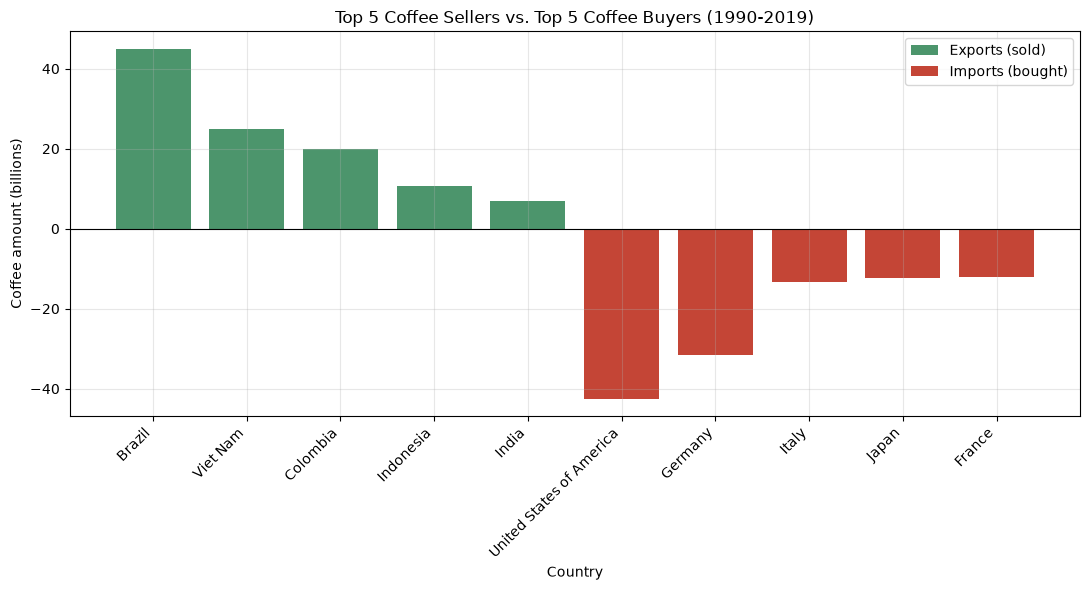

In [21]:
top_sellers = balance.head(5)
top_buyers = balance.tail(5).sort_values('Trade_balance')
combo = pd.concat([top_sellers, top_buyers])

fig, ax = plt.subplots()
idx = np.arange(len(combo))
ax.bar(idx, combo['Total_export'] / 1e9, label='Exports (sold)', color='#4c956c')
ax.bar(idx, -combo['Total_import'] / 1e9, label='Imports (bought)', color='#c44536')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(idx)
ax.set_xticklabels(combo.index, rotation=45, ha='right')
ax.set_ylabel('Coffee amount (billions)')
ax.set_xlabel('Country')
ax.set_title('Top 5 Coffee Sellers vs. Top 5 Coffee Buyers (1990-2019)')
ax.legend()
plt.tight_layout()
plt.show()

### Chart 2 - Coffee exports over time

This adds up every country's exports for each year. **Coffee exports have gone up over the years**, which means the world keeps trading more and more coffee.

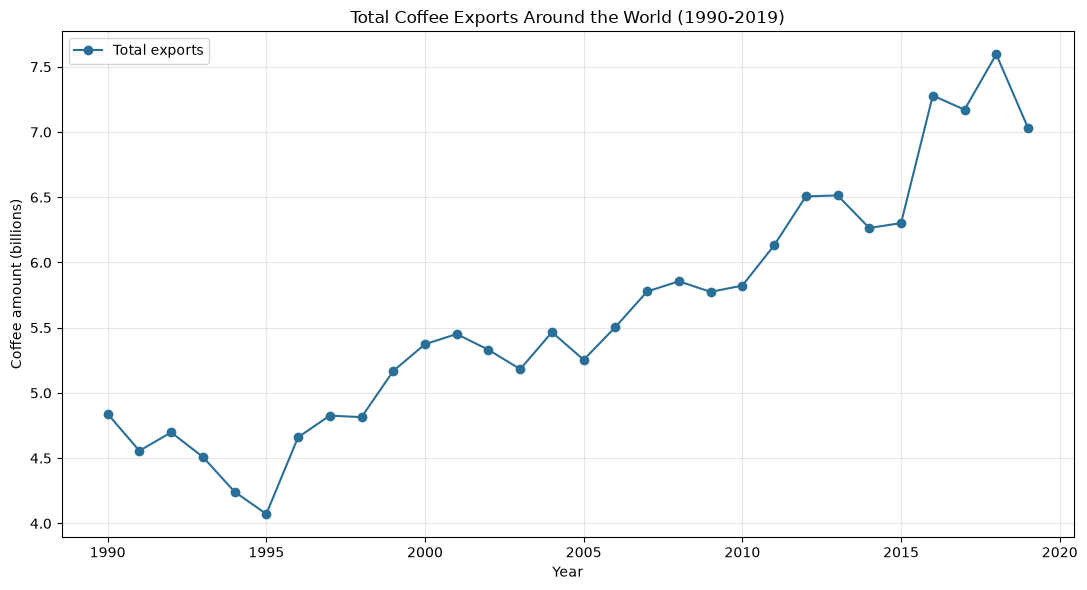

In [22]:
global_exports = export_df[export_years].sum(axis=0)
global_exports.index = [int(y) for y in export_years]

fig, ax = plt.subplots()
ax.plot(global_exports.index, global_exports.values / 1e9,
        marker='o', color='#2a6f97', label='Total exports')
ax.set_xlabel('Year')
ax.set_ylabel('Coffee amount (billions)')
ax.set_title('Total Coffee Exports Around the World (1990-2019)')
ax.legend()
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f'))
plt.tight_layout()
plt.show()

### Chart 3 - Share of each coffee type

This shows how much of the world's coffee is each type. **Arabica-type coffee makes up most of what is grown, and plain Robusta is the smallest slice.**

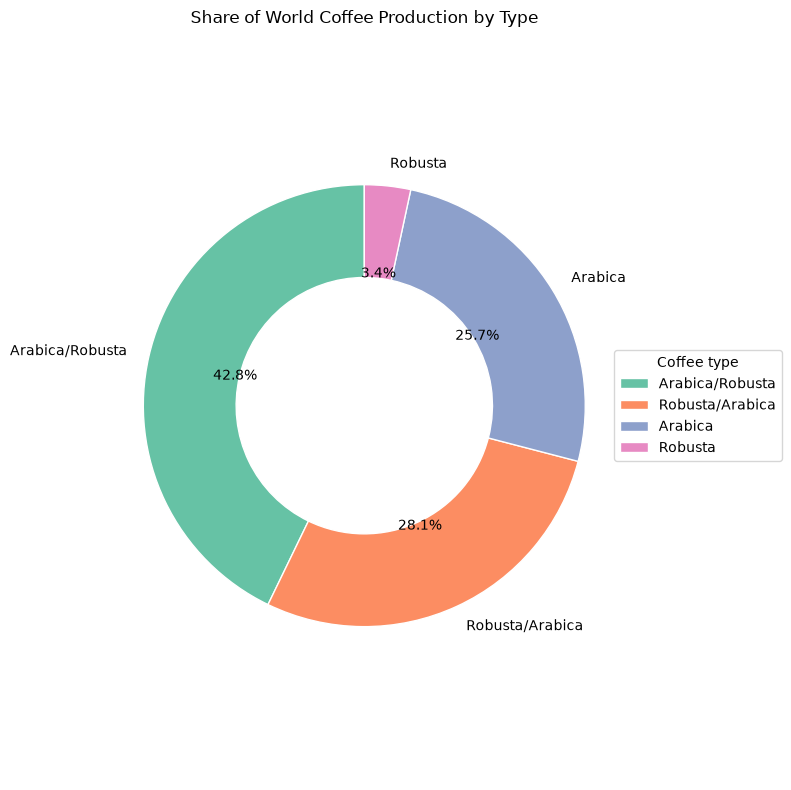

In [23]:
fig, ax = plt.subplots(figsize=(8, 8))
colors = plt.cm.Set2.colors
wedges, texts, autotexts = ax.pie(
    type_totals.values,
    labels=type_totals.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    wedgeprops=dict(width=0.42, edgecolor='white'),
)
ax.set_title('Share of World Coffee Production by Type')
ax.legend(wedges, type_totals.index, title='Coffee type',
          loc='center left', bbox_to_anchor=(1, 0.5))
ax.axis('equal')
plt.tight_layout()
plt.show()

After cleaning and studying the export, import, and production data from 1990 to 2019, there is a clear split in where coffee is grown versus where it is used. Almost all of the coffee in the world is grown in a small group of countries near the equator, like Brazil, Viet Nam, and Colombia. But the coffee is mostly drank far away in richer countries like the United States, Germany, and Italy, and those buyer countries grow basicaly no coffee of their own. Over time this gap has gotten bigger, not smaller, and total exports keep climbing year after year, which means the world is leaning on this long supply chain more and more.

The biggest risk the numbers show is how much the world relies on just a tiny handful of giant producers. Brazil by itself sells way more coffee than anyone else, and it also had the largest change in production over the years. When one or two countries carry that much of the supply, that is a serious problem, because if Brazil has a bad year from a drought, a frost, or a shipping issue, prices everywhere could jump and we could struggle to get enough beans. Most production is also one coffee type, Arabica, so a disease or weather event that hurts that type would hit us hard too.

My recommendation is to spread out where we buy from so we are not so dependant on one country. We should keep Brazil as a key partner because it is huge and steady, but we also need long-term deals with the other reliable sellers like Viet Nam and Colombia. On top of that, we should build relationships with smaller rising producers such as Peru, Honduras, and Ethiopia so we have backup options if a big supplier fails, and we should buy more than one coffee type so a problem with Arabica does not wreck everything. Spreading out our partners now is the safest way to keep our coffee supply secure for years to come.